In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/2")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    # ローカル環境の場合、プロジェクトルートをパスに追加
    proj_root = Path.cwd().resolve()
    if proj_root.name == "2":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 第2章 EDK II入門とメモリマップ — 2.2 EDK IIでハローワールド (`osbook_day02a`) (含 コラム2.1: インクルード)

本節では、名著『**ゼロからのOS自作入門**』（内田公太 著、マイナビ出版）の **第2章 2.2「EDK IIでハローワールド」**（Gitタグ `osbook_day02a`）および **コラム2.1「インクルード」** に基づき、自作ブートローダ **`MikanLoaderPkg`** の構成、C言語による UEFI アプリケーション `Main.c` の実装、UEFI ABI / 呼び出し規約、および Cプリプロセッサのテキスト展開・探索パス・多重インクルード防止メカニズムを徹底解説します。

---

## 🎯 本節の学習目標と技術的動機

1. **`MikanLoaderPkg` の完全なパッケージ構成を把握する**:
   - 前節（2.1節）で学んだ EDK II のパッケージ仕様（`.dec`, `.dsc`, `.inf`）を実機コードに適用し、自作ブートローダのディレクトリツリーとメタ定義ファイルの記述内容を理解します。
2. **UEFI アプリケーションのエントリポイント `UefiMain` と ABI を習得する**:
   - `EFI_STATUS`, `EFI_HANDLE`, `EFI_SYSTEM_TABLE*` の引数仕様、Microsoft x64 呼び出し規約（`EFIAPI`）、および UEFI ステータスコードの 64ビット最上位エラービット構造を数理的に導出します。
3. **`Print(L\"...\")` と UTF-16LE ワイド文字列のメモリ構造を解剖する**:
   - なぜ UEFI ではワイド文字列（`L\"...\"`, `CHAR16`）が標準なのか、Little-Endian バイト列配置（各文字 2 バイト + null 終端 `0x0000`）を解析します。
4. **ブートローダにおける `while (1);` 無限ループの必然性を理解する**:
   - なぜ `UefiMain` から安易に `return` してはならないのか、ファームウェア（UEFI Boot Manager / UEFI Shell）への早期復帰と画面クリアの問題を把握します。
5. **コラム2.1: プリプロセッサ `#include` の展開動作を数理・木構造で完全解明する**:
   - Cコンパイルパイプラインにおけるプリプロセッサ（CPP: *C Preprocessor*）のテキスト置換動作、`<...>`（システムインクルードパス）と `"..."`（カレントディレクトリ優先）の厳密な探索規則、多重インクルードガード（`#ifndef` / `#define` / `#endif` vs `#pragma once`）による重複定義エラー（*Redefinition*）防止、および数行のソースから数万行に膨張する *Include Bloat* の実態を解明します。
6. **C++20 による対話型コンパイル検証 & Python シミュレーション**:
   - ホスト環境上で C++20 による UEFI コンソール出力とプリプロセッサシミュレータを対話的にビルド・実行し、理解を深めます。


## 1. なぜ手書き C から EDK II パッケージへの移行が必要だったのか？

### 1.1 第1章の手書き Freestanding C方式の限界
第1章（1.9節）では、標準ヘッダに依存しない最小構成の C 言語コードを手動でコンパイルしました：

```c
// 第1章 1.9節: 最小限の手書き構造体による文字表示
struct EFI_SYSTEM_TABLE {
    char dummy[52];
    void* ConsoleOutHandle;
    struct EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL* ConOut;
};
```

この方法は「UEFI のバイナリが動く最小の仕組み」を理解する上では極めて明快でしたが、以下の実用的課題を抱えていました：
1. **構造体定義の手動保守が不可能**: UEFI 2.8+ 仕様書は 2,500 ページ以上に及び、画面描画（GOP）、メモリマップ取得、ファイル入出力などの膨大な構造体を 1 バイトのパディングミスもなく自前定義するのは不可能です。
2. **文字列フォーマット機能の欠如**: `ConOut->OutputString` は静的な UTF-16 文字列しか出力できず、数値や変数を整形出力する `printf` / `Print` 機能がありません。
3. **初期化コードの欠落**: EDK II の公式アプリケーションでは、エントリポイント前に `gST` (System Table) や `gBS` (Boot Services) を初期化するラッパーコード（`AutoGen.c`）が自動合成されますが、手書きではこれらを自力で管理しなければなりません。

### 1.2 公式タグ `osbook_day02a` の位置づけ
本書の Git リポジトリにおける `osbook_day02a` は、EDK II の標準パッケージシステム上に自作ブートローダ **`MikanLoaderPkg`** を初めて構築し、EDK II の高水準ライブラリ `UefiLib` の `Print()` 関数を用いて画面に「Hello, Mikan World!」を表示する記念碑的ステップです。


## 2. `MikanLoaderPkg` のディレクトリ構成とメタ定義

EDK II におけるパッケージは、独立したディレクトリとして管理されます。自作ブートローダ `MikanLoaderPkg` は、EDK II のリポジトリルート（`$HOME/edk2`）直下にシンボリックリンクまたは配置されます。

```text
edk2/
 ├── MdePkg/                     # UEFI標準仕様の宣言とライブラリインターフェース
 │    ├── MdePkg.dec
 │    └── Include/
 │         ├── Uefi.h
 │         └── Library/UefiLib.h
 └── MikanLoaderPkg/             # 自作ブートローダパッケージ
      ├── MikanLoaderPkg.dec     # パッケージ公開宣言
      ├── MikanLoaderPkg.dsc     # プラットフォームビルド記述 (依存性注入)
      ├── Loader.inf             # ブートローダモジュール情報
      └── Main.c                 # C言語ソースコード (osbook_day02a)
```

### 2.1 各メタ定義ファイルの役割と記述内容

#### (1) `MikanLoaderPkg/MikanLoaderPkg.dec` (Package Declaration)
自パッケージの名前と GUID、バージョンを宣言します：
```ini
[Defines]
  DEC_SPECIFICATION              = 0x00010005
  PACKAGE_NAME                   = MikanLoaderPkg
  PACKAGE_GUID                   = 452eae8e-71e9-11e8-a243-df3f1ffdebe1
  PACKAGE_VERSION                = 0.1

[Includes]
  Include
```

#### (2) `MikanLoaderPkg/Loader.inf` (Module Information)
単一モジュール（`Loader.efi`）のメタ情報を定義します：
```ini
[Defines]
  INF_VERSION                    = 0x00010006
  BASE_NAME                      = Loader
  FILE_GUID                      = c9d0d202-71e9-11e8-9e52-cfbfd0063fbf
  MODULE_TYPE                    = UEFI_APPLICATION
  VERSION_STRING                 = 0.1
  ENTRY_POINT                    = UefiMain

[Sources]
  Main.c

[Packages]
  MdePkg/MdePkg.dec

[LibraryClasses]
  UefiLib
  UefiApplicationEntryPoint
```

> [!NOTE]
> `Loader.inf` では「ソースファイルが `Main.c` であること」「エントリポイントが `UefiMain` であること」「標準パッケージ `MdePkg/MdePkg.dec` を利用すること」「抽象ライブラリ `UefiLib` と `UefiApplicationEntryPoint` を要求すること」を宣言しています。具象実装への結合（バインド）は次項の DSC で行われます。

#### (3) `MikanLoaderPkg/MikanLoaderPkg.dsc` (Platform Description)
ビルド対象のコンポーネントと、ライブラリクラスの具象実装を **依存性注入 (Dependency Injection)** します：
```ini
[Defines]
  PLATFORM_NAME                  = MikanLoaderPkg
  PLATFORM_GUID                  = d3fd43f1-71e9-11e8-8a87-3770f907be79
  PLATFORM_VERSION               = 0.1
  DSC_SPECIFICATION              = 0x00010005
  OUTPUT_DIRECTORY               = Build/MikanLoaderX64
  SUPPORTED_ARCHITECTURES        = X64
  BUILD_TARGETS                  = DEBUG|RELEASE|NOOPT

[LibraryClasses]
  UefiApplicationEntryPoint|MdePkg/Library/UefiApplicationEntryPoint/UefiApplicationEntryPoint.inf
  UefiLib|MdePkg/Library/UefiLib/UefiLib.inf
  BaseLib|MdePkg/Library/BaseLib/BaseLib.inf
  BaseMemoryLib|MdePkg/Library/BaseMemoryLib/BaseMemoryLib.inf
  PrintLib|MdePkg/Library/BasePrintLib/BasePrintLib.inf
  PcdLib|MdePkg/Library/BasePcdLibNull/BasePcdLibNull.inf
  MemoryAllocationLib|MdePkg/Library/UefiMemoryAllocationLib/UefiMemoryAllocationLib.inf
  UefiBootServicesTableLib|MdePkg/Library/UefiBootServicesTableLib/UefiBootServicesTableLib.inf
  UefiRuntimeServicesTableLib|MdePkg/Library/UefiRuntimeServicesTableLib/UefiRuntimeServicesTableLib.inf
  DevicePathLib|MdePkg/Library/UefiDevicePathLib/UefiDevicePathLib.inf

[Components]
  MikanLoaderPkg/Loader.inf
```


In [2]:
# Python による MikanLoaderPkg の EDK II パッケージモデル & 依存性注入の検証
from common.os_sim import (
    Edk2InfModel,
    Edk2DscModel,
    DscDependencyResolver,
)

loader_inf_content = """
[Defines]
  INF_VERSION                    = 0x00010006
  BASE_NAME                      = Loader
  FILE_GUID                      = c9d0d202-71e9-11e8-9e52-cfbfd0063fbf
  MODULE_TYPE                    = UEFI_APPLICATION
  VERSION_STRING                 = 0.1
  ENTRY_POINT                    = UefiMain

[Sources]
  Main.c

[Packages]
  MdePkg/MdePkg.dec

[LibraryClasses]
  UefiLib
  UefiApplicationEntryPoint
"""

loader_inf = Edk2InfModel.parse_inf_text(loader_inf_content)
print("=== Loader.inf 解析結果 ===")
print(f"モジュール名: {loader_inf.base_name}")
print(f"モジュール型: {loader_inf.module_type}")
print(f"エントリポイント: {loader_inf.entry_point}")
print(f"要求ライブラリクラス: {loader_inf.library_classes}")
print(f"依存パッケージ: {loader_inf.packages}")

assert loader_inf.base_name == "Loader"
assert loader_inf.entry_point == "UefiMain"
assert "UefiLib" in loader_inf.library_classes
print("\n[PASS] Loader.inf のメタ定義検証に成功しました！")


=== Loader.inf 解析結果 ===
モジュール名: Loader
モジュール型: UEFI_APPLICATION
エントリポイント: UefiMain
要求ライブラリクラス: ['UefiLib', 'UefiApplicationEntryPoint']
依存パッケージ: ['MdePkg/MdePkg.dec']

[PASS] Loader.inf のメタ定義検証に成功しました！


## 3. `Main.c` (`osbook_day02a`) の C 実装徹底解剖と UEFI ABI

第2章 2.2節で記述する `Main.c` のソースコードは、わずか 11 行のシンプルなプログラムです：

```c
#include <Uefi.h>
#include <Library/UefiLib.h>

EFI_STATUS EFIAPI UefiMain(
    EFI_HANDLE ImageHandle,
    EFI_SYSTEM_TABLE *SystemTable)
{
  Print(L"Hello, Mikan World!\n");
  while (1);
  return EFI_SUCCESS;
}
```

この短いコードの 1 行 1 行に、UEFI アーキテクチャとハードウェア制御の根幹が凝縮されています。

---

### 3.1 ヘッダインクルードの役割
1. **`#include <Uefi.h>`**:
   - EDK II の `MdePkg/Include/Uefi.h` です。
   - `EFI_STATUS` (戻り値型), `EFI_HANDLE` (ハンドル型), `EFI_SYSTEM_TABLE` (システムテーブル構造体), `CHAR16` (16ビット文字型) など、UEFI 仕様で規定された全基本型とプロトコルインターフェースが定義されています。
2. **`#include <Library/UefiLib.h>`**:
   - EDK II の高水準ユーティリティ関数ライブラリです。
   - `Print()` 関数（書式付きワイド文字列出力）の関数プロトタイプ宣言を含みます。

---

### 3.2 エントリポイント `UefiMain` のシグネチャと呼び出し規約

#### (1) `EFIAPI` 呼び出し規約 (Microsoft x64 ABI)
x86-64 アーキテクチャにおける一般的な Linux C コンパイラは **System V AMD64 ABI**（引数を `RDI`, `RSI`, `RDX`, `RCX`, `R8`, `R9` で渡す）を使用します。しかし、UEFI ファームウェアは Intel と Microsoft の歴史的経緯から **Microsoft x64 ABI** を採用しています：

| 引数順序 | レジスタ (Microsoft x64 ABI / `EFIAPI`) | レジスタ (System V AMD64 ABI / Linux) |
|:---:|:---:|:---:|
| 第1引数 (`ImageHandle`) | **`RCX`** | `RDI` |
| 第2引数 (`SystemTable`) | **`RDX`** | `RSI` |
| 第3引数 | **`R8`** | `RDX` |
| 第4引数 | **`R9`** | `RCX` |
| Shadow Space | **呼び出し元がスタック上に 32 バイト確保必須** | 不要 (Red Zone 128 バイト利用可) |

`EFIAPI` マクロは、Clang / GCC において `__attribute__((ms_abi))` に展開され、コンパイラに対して「この関数は Microsoft x64 呼び出し規約に従ってレジスタとスタックを操作せよ」と指示します。

#### (2) `EFI_STATUS` のビット構造とエラー判定数理
`EFI_STATUS` は 64 ビット符号なし整数（`UINT64`）です。最上位ビット（Bit 63: 最上位ビットマスク `0x8000_0000_0000_0000`）がエラーフラグを表します：

$$\text{IsError}(\text{status}) = (\text{status} \land 2^{63}) \neq 0$$
$$\text{ErrorCode}(\text{status}) = \text{status} \land (2^{63} - 1)$$

- `EFI_SUCCESS = 0x00000000_00000000` (最上位ビット 0: 正常終了)
- `EFI_LOAD_ERROR = 0x80000000_00000001` (最上位ビット 1: ロード失敗)
- `EFI_BUFFER_TOO_SMALL = 0x80000000_00000005` (最上位ビット 1: バッファ不足 ※第2章 2.5節で頻出)

#### (3) `EFI_HANDLE ImageHandle` と `EFI_SYSTEM_TABLE *SystemTable`
- `ImageHandle`: ロードされたブートローダ自身を識別するための不透明ポインタ（ファームウェア内部管理オブジェクト）。自イメージの配置されたストレージやデバイスパスの取得に使用します。
- `SystemTable`: ファームウェアが提供するあらゆる機能のマスターハブ構造体へのポインタ。コンソール入出力（`ConIn`, `ConOut`）やブートサービス（`BootServices`）への関数ポインタ配列を内包しています。

---

### 3.3 `Print(L\"Hello, Mikan World!\\n\")` と UTF-16LE ワイド文字列

C言語の通常の文字列リテラル `"Hello"` は 1 文字 1 バイトの ASCII/UTF-8 ですが、プレフィックス **`L`** を付けた `L"Hello"` は **ワイド文字列リテラル (Wide String Literal)** となり、各文字が **16ビット符号なし整数（`CHAR16` = `char16_t`）** で表現されます。

x86-64 CPU は **リトルエンディアン (Little-Endian)** であるため、16ビット整数 `0x0048` ('H') はメモリ上で `[0x48, 0x00]` の順序で格納されます：

```text
文字 'H' (U+0048) -> メモリ配置: [ 0x48 ][ 0x00 ]
文字 'e' (U+0065) -> メモリ配置: [ 0x65 ][ 0x00 ]
文字 '\n'(U+000A) -> メモリ配置: [ 0x0A ][ 0x00 ]
終端 '\0'(U+0000) -> メモリ配置: [ 0x00 ][ 0x00 ]
```

`Print()` 関数は、内部で `SystemTable->ConOut->OutputString(SystemTable->ConOut, ...)` を呼び出し、UEFI ファームウェアが持っているフォントグリフ（文字ビットマップ）をグラフィックスフレームバッファ（GOP）へラスタライズして画面に描画します。

---

### 3.4 なぜ `while (1);` 無限ループが必要なのか？

> [!IMPORTANT]
> **ブートローダが勝手に return してはならない理由**:
> 通常のデスクトップアプリケーション（OS上で動くアプリ）は処理が終われば `return 0;` でシェルに戻ります。
> しかし、PC起動直後の UEFI 環境においてブートローダが `return EFI_SUCCESS;` してしまうと、**制御が直ちに UEFI ファームウェア（Boot Manager / UEFI Shell）に返却** されます。
> 多くの UEFI ファームウェアは画面を即座に再描画・クリアするか、シェルプロンプト（`Shell>`）に戻ってしまうため、画面にせっかく表示された「Hello, Mikan World!」が一瞬で消えてしまいます。
> そのため、カーネルロード機能を実装する前の本節では、`while (1);`（アセンブリの `jmp .`）で CPU を無限ループさせ、描画画面を静止させて肉眼で結果を確認できるようにしています。


In [3]:
# Python による UEFI Status コードビット演算と UTF-16LE メモリレイアウト解析
import pandas as pd
from common.os_sim import UefiStatus, UefiStringEncoder

print("=== 1. UEFI ステータスコード最上位エラービット解析 ===")
statuses = [
    UefiStatus.SUCCESS,
    UefiStatus.LOAD_ERROR,
    UefiStatus.INVALID_PARAMETER,
    UefiStatus.UNSUPPORTED,
    UefiStatus.BUFFER_TOO_SMALL,
]

status_records = []
for s in statuses:
    status_records.append({
        "ステータス名": UefiStatus.name(s),
        "16進数表現": UefiStatus.to_hex(s),
        "Bit 63 (エラーフラグ)": 1 if UefiStatus.is_error(s) else 0,
        "エラー番号": UefiStatus.error_code(s),
        "判定結果": "ERROR" if UefiStatus.is_error(s) else "SUCCESS",
    })

df_status = pd.DataFrame(status_records)
display(df_status)

print("\n=== 2. L\"Hello, Mikan World!\\n\" の UTF-16LE メモリレイアウト ===")
text = "Hello, Mikan World!\n"
layout = UefiStringEncoder.analyze_memory_layout(text)
df_layout = pd.DataFrame(layout)
print(f"総文字数 (null終端含む): {len(layout)} ワード ({len(layout) * 2} バイト)")
display(df_layout.head(10)) # 先頭10文字を表示


=== 1. UEFI ステータスコード最上位エラービット解析 ===


,ステータス名,16進数表現,Bit 63 (エラーフラグ),エラー番号,判定結果
0,EFI_SUCCESS,0x0000000000000000,0,0,SUCCESS
1,EFI_LOAD_ERROR,0x8000000000000001,1,1,ERROR
2,EFI_INVALID_PARAMETER,0x8000000000000002,1,2,ERROR
3,EFI_UNSUPPORTED,0x8000000000000003,1,3,ERROR
4,EFI_BUFFER_TOO_SMALL,0x8000000000000005,1,5,ERROR



=== 2. L"Hello, Mikan World!\n" の UTF-16LE メモリレイアウト ===
総文字数 (null終端含む): 21 ワード (42 バイト)


,offset,hex_bytes,uint16_val,char
0,0,48 00,0x0048,H
1,2,65 00,0x0065,e
2,4,6C 00,0x006C,l
3,6,6C 00,0x006C,l
4,8,6F 00,0x006F,o
5,10,2C 00,0x002C,","
6,12,20 00,0x0020,
7,14,4D 00,0x004D,M
8,16,69 00,0x0069,i
9,18,6B 00,0x006B,k


## 4. 【図版再現】EDK II Hello World の実行制御フローとメモリ状態 (Figure 2.3)

PC の電源投入（CPU リセットベクタ）から、ファームウェア初期化、ブートローダロード、`UefiMain` 実行、そして `while(1);` による静止までの全シーケンスを可視化します。

- **Phase 1: ファームウェア初期化 & BDS (Boot Device Select)**
  - SEC → PEI → DXE と進み、`EFI_SYSTEM_TABLE` と `EFI_BOOT_SERVICES` が RAM 上に構築されます。
  - BDS が FAT32 ストレージの `\EFI\BOOT\BOOTX64.EFI`（`Loader.efi`）を検出し、PE32+ 形式のバイナリを RAM に展開・再配置（Relocation）します。
- **Phase 2: Loader.efi 内部実行**
  - BaseTools が自動生成したエントリラッパー `_ModuleEntryPoint` がグローバル変数 `gST`, `gBS`, `gImageHandle` を初期化します。
  - `UefiMain` が呼び出され、`Print(L"...")` が実行されます。
- **Phase 3: テキスト出力と CPU 静止**
  - `SystemTable->ConOut->OutputString()` がファームウェアのフォントを展開し、VRAM (GOP フレームバッファ) に文字を描画します。
  - `while (1);` ループにより CPU が静止し、画面表示が永続保持されます。


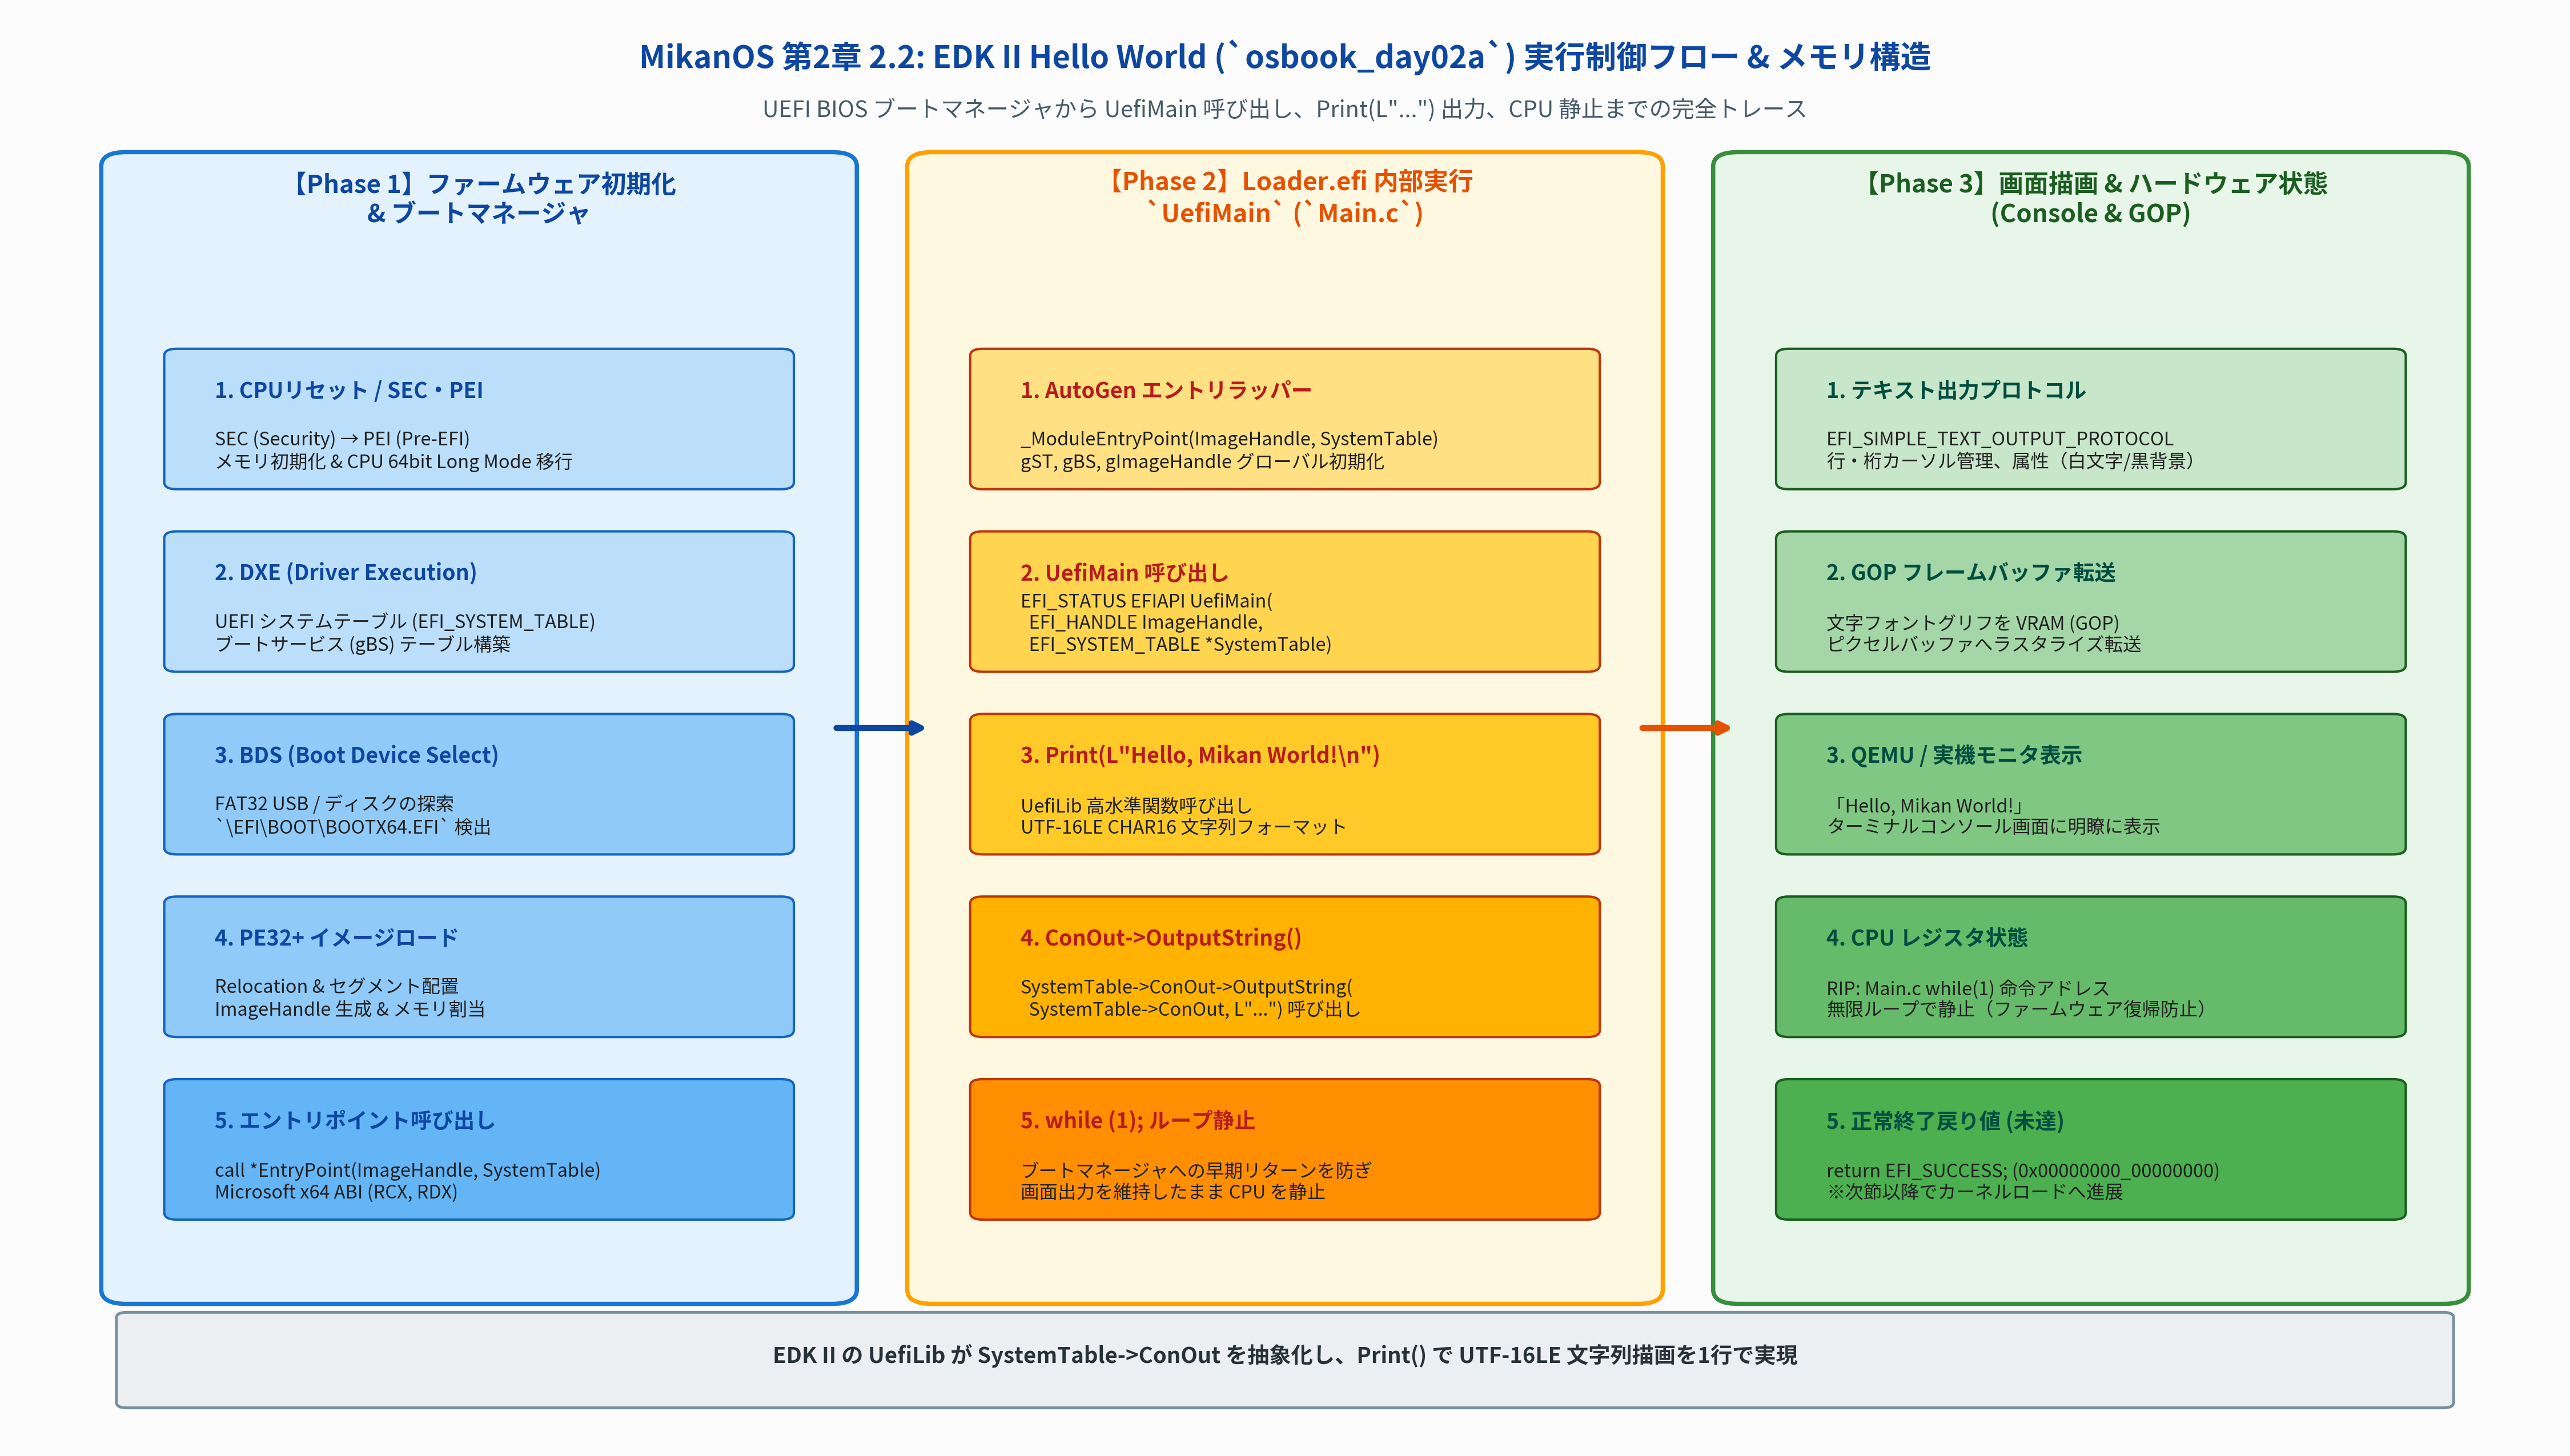

In [4]:
# Figure 2.3 のプロット生成と表示
from pathlib import Path
from IPython.display import Image, display
from common.os_sim import plot_uefi_hello_world_execution_flow

fig_path = Path("result/fig2_03_uefi_hello_world_execution_flow.png")
plot_uefi_hello_world_execution_flow(fig_path)
display(Image(filename=str(fig_path)))


## 5. 【コラム2.1 徹底解説】プリプロセッサ `#include` の展開動作と探索規則

本節に付随する **コラム2.1「インクルード」** では、C言語学習者が何気なく書いている `#include` ディレクティブが、コンパイラ内部で一体何を行っているのかを深く掘り下げています。

---

### 5.1 C言語のコンパイルパイプラインとプリプロセッサの役割
C言語のビルドプロセスは、単一の工程ではなく以下の 4 つの独立した段階から成り立っています：

```mermaid
flowchart LR
    A["ソースコード<br>(Main.c)"] --> B["1. プリプロセッサ<br>(CPP: -E)"]
    B --> C["プリプロセス済みC<br>(Main.i)"]
    C --> D["2. Cコンパイラ本体<br>(cc1: -S)"]
    D --> E["アセンブリコード<br>(Main.s)"]
    E --> F["3. アセンブラ<br>(as: -c)"]
    F --> G["オブジェクトファイル<br>(Main.o / .obj)"]
    G --> H["4. リンカ<br>(ld / lld-link)"]
    H --> I["最終実行バイナリ<br>(Loader.efi)"]
```

プリプロセッサ（*CPP: C Preprocessor*）は、**「Cコンパイラ本体が構文解析（AST構築）を行う前に動作するテキスト置換エンジン」** です。
この段階では、型チェックや関数呼び出しの文法検査は一切行われません。プリプロセッサが行うのは以下の 3 つだけです：
1. **コメントの除去**: `/* ... */` や `// ...` を空白文字に置換。
2. **マクロ定義と置換**: `#define` による定数・マクロの文字列置換。
3. **ファイルの丸ごとインクルード**: `#include` で指定されたファイルの内容をその場に**「丸ごとコピペ（テキスト展開）」**。

---

### 5.2 `#include <...>` と `#include "..."` の決定論的探索規則

C言語規格（ISO C）および主要コンパイラ（Clang, GCC, MSVC）において、山括弧 `<>` と二重引用符 `""` には厳格な探索パスの優先順位が定められています：

| インクルード記法 | 探索優先順位 | 主な用途 |
|:---|:---|:---|
| **`#include <Header.h>`** | 1. コンパイラ引数 `-I` で指定されたシステムインクルードディレクトリ群<br>2. コンパイラ組み込み標準インクルードパス | 標準Cライブラリ、UEFI標準ヘッダ（`Uefi.h`, `UefiLib.h`） |
| **`#include "Header.h"`** | 1. **インクルード元ソースファイルが存在するカレントディレクトリ**<br>2. （見つからなければ）`-I` で指定されたシステムインクルードディレクトリ群 | 同一プロジェクト内のプライベートヘッダ |

> [!NOTE]
> **EDK II におけるインクルード解決の仕組み**:
> `Main.c` では `#include <Uefi.h>` と記述されていますが、なぜコンパイラは `MdePkg/Include/Uefi.h` の場所を知ることができるのでしょうか？
> それは、`Loader.inf` の `[Packages]` に `MdePkg/MdePkg.dec` が指定されており、`MdePkg.dec` の `[Includes]` に `Include` が定義されているためです。
> EDK II の `build` コマンドは、これらを自動解析して Clang / GCC に対して **`-I $EDK_PATH/MdePkg/Include`** フラグを自動注入します。

---

### 5.3 多重インクルード問題とインクルードガードの数理

#### (1) 多重定義エラー (*Redefinition*) の発生メカニズム
`Main.c` が `#include <Uefi.h>` と `#include <Library/UefiLib.h>` をインクルードしたとします。しかし、`UefiLib.h` 自体も内部で `Uefi.h` の型を必要とするため `#include <Uefi.h>` を記述しています。

もしインクルードガードが無ければ、プリプロセッサは愚直にファイルを展開するため、`Main.i`（展開後ソース）の中に `struct EFI_SYSTEM_TABLE { ... }` の定義が **2 回出現** してしまいます。
C言語では同一スコープ内で構造体や型の再定義が禁じられているため、コンパイラは即座にコンパイルエラー（`error: redefinition of 'struct EFI_SYSTEM_TABLE'`）を出して停止します。

#### (2) 伝統的インクルードガード (`#ifndef` / `#define` / `#endif`)
この問題を回避するため、すべての UEFI ヘッダには以下のような **インクルードガード (Include Guard)** が施されています：

```c
// MdePkg/Include/Uefi.h の先頭
#ifndef __UEFI_H__
#define __UEFI_H__

// ヘッダの内容（型定義、構造体、関数プロトタイプ）
struct EFI_SYSTEM_TABLE { ... };

#endif // __UEFI_H__
```

- **1回目のインクルード時**: `__UEFI_H__` は未定義なので `#ifndef` が真となり、内容が展開され、直後に `#define __UEFI_H__` でマクロが定義されます。
- **2回目のインクルード時**: `__UEFI_H__` は既に定義済みなので `#ifndef` が偽となり、プリプロセッサは `#endif` までの全行を一瞬で読み飛ばします。

#### (3) `#pragma once` との比較
現代のコンパイラ（Clang, GCC, MSVC）は、より簡潔な非標準ディレクティブ **`#pragma once`** をサポートしています。
`#pragma once` はファイルシステムの inode やパスをコンパイラ自身が記憶し、「この物理ファイルは 2 回目以降オープンすらしない」という最適化を行うため、大規模プロジェクトにおいてプリプロセスを高速化できます。EDK II の標準ヘッダでは安全のため伝統的マクロガードと併用されることが一般的です。

---

### 5.4 インクルードツリー（木構造）とコード量の爆発 (*Include Bloat*)
`Main.c` はたったの 11 行ですが、`Uefi.h` や `UefiLib.h` が間接的にインクルードするヘッダの依存ツリー（Include Tree）を展開すると、最終的なプリプロセス後ソース（`Main.i`）は **数万行** に膨れ上がります。
次セルの Python シミュレータで、この展開挙動を実際に測定・検証してみましょう。


In [5]:
# Python による C プリプロセッサシミュレータの実演
from common.os_sim import CPreprocessorSimulator

cpp_sim = CPreprocessorSimulator()
cpp_sim.add_include_dir("MdePkg/Include")

# 1. MdePkg 標準ヘッダの仮想登録 (インクルードガード付き)
cpp_sim.add_file("MdePkg/Include/Uefi/UefiBaseType.h", """#ifndef __UEFI_BASE_TYPE_H__
#define __UEFI_BASE_TYPE_H__
typedef unsigned long long UINTN;
typedef char16_t CHAR16;
typedef UINTN EFI_STATUS;
#endif
""")

cpp_sim.add_file("MdePkg/Include/Uefi/UefiSpec.h", """#ifndef __UEFI_SPEC_H__
#define __UEFI_SPEC_H__
#include <Uefi/UefiBaseType.h>
struct EFI_SYSTEM_TABLE {
    void* ConOut;
};
#endif
""")

cpp_sim.add_file("MdePkg/Include/Uefi.h", """#ifndef __UEFI_H__
#define __UEFI_H__
#include <Uefi/UefiBaseType.h>
#include <Uefi/UefiSpec.h>
#endif
""")

cpp_sim.add_file("MdePkg/Include/Library/UefiLib.h", """#ifndef __UEFI_LIB_H__
#define __UEFI_LIB_H__
#include <Uefi.h>
EFI_STATUS Print(const CHAR16* Format, ...);
#endif
""")

# 2. MikanLoaderPkg Main.c の仮想登録
cpp_sim.add_file("MikanLoaderPkg/Main.c", """#include <Uefi.h>
#include <Library/UefiLib.h>

EFI_STATUS EFIAPI UefiMain(
    EFI_HANDLE ImageHandle,
    EFI_SYSTEM_TABLE *SystemTable)
{
  Print(L"Hello, Mikan World!\n");
  while (1);
  return EFI_SUCCESS;
}
""")

res = cpp_sim.preprocess("MikanLoaderPkg/Main.c")
print("=== C Preprocessor シミュレーション結果 ===")
print(f"元のソースコード行数: {res.source_line_count} 行")
print(f"展開後のコード行数:   {res.expanded_line_count} 行")
print(f"インクルードされたファイル順序: {res.included_files_in_order}")
print(f"定義されたガードシンボル:       {res.guard_symbols_defined}")

print("\n--- 展開されたソースコードの抜粋 ---")
for line in res.expanded_code.splitlines()[:15]:
    print("  |", line)


=== C Preprocessor シミュレーション結果 ===
元のソースコード行数: 12 行
展開後のコード行数:   37 行
インクルードされたファイル順序: ['MdePkg/Include/Uefi.h', 'MdePkg/Include/Uefi/UefiBaseType.h', 'MdePkg/Include/Uefi/UefiSpec.h', 'MdePkg/Include/Uefi/UefiBaseType.h', 'MdePkg/Include/Library/UefiLib.h', 'MdePkg/Include/Uefi.h']
定義されたガードシンボル:       ['__UEFI_H__', '__UEFI_BASE_TYPE_H__', '__UEFI_SPEC_H__', '__UEFI_LIB_H__']

--- 展開されたソースコードの抜粋 ---
  | /* >>> BEGIN EXPAND: Uefi.h (MdePkg/Include/Uefi.h) */
  | #ifndef __UEFI_H__
  | #define __UEFI_H__
  | /* >>> BEGIN EXPAND: Uefi/UefiBaseType.h (MdePkg/Include/Uefi/UefiBaseType.h) */
  | #ifndef __UEFI_BASE_TYPE_H__
  | #define __UEFI_BASE_TYPE_H__
  | typedef unsigned long long UINTN;
  | typedef char16_t CHAR16;
  | typedef UINTN EFI_STATUS;
  | /* <<< END EXPAND: Uefi/UefiBaseType.h */
  | /* >>> BEGIN EXPAND: Uefi/UefiSpec.h (MdePkg/Include/Uefi/UefiSpec.h) */
  | #ifndef __UEFI_SPEC_H__
  | #define __UEFI_SPEC_H__
  | /* >>> BEGIN EXPAND: Uefi/UefiBaseType.h (MdePkg/Include/Uefi

## 6. 【図版再現】プリプロセッサ `#include` 展開メカニズムと多重インクルード防止 (Figure 2.4)

左パネルではプリプロセッサによるテキスト展開（コピペ）の様子と `<...>` vs `"..."` の探索パス遷移を、右パネルでは `MikanLoaderPkg` のインクルード依存木（Include Tree）とインクルードガードによる多重定義防止ロジックを図解します。


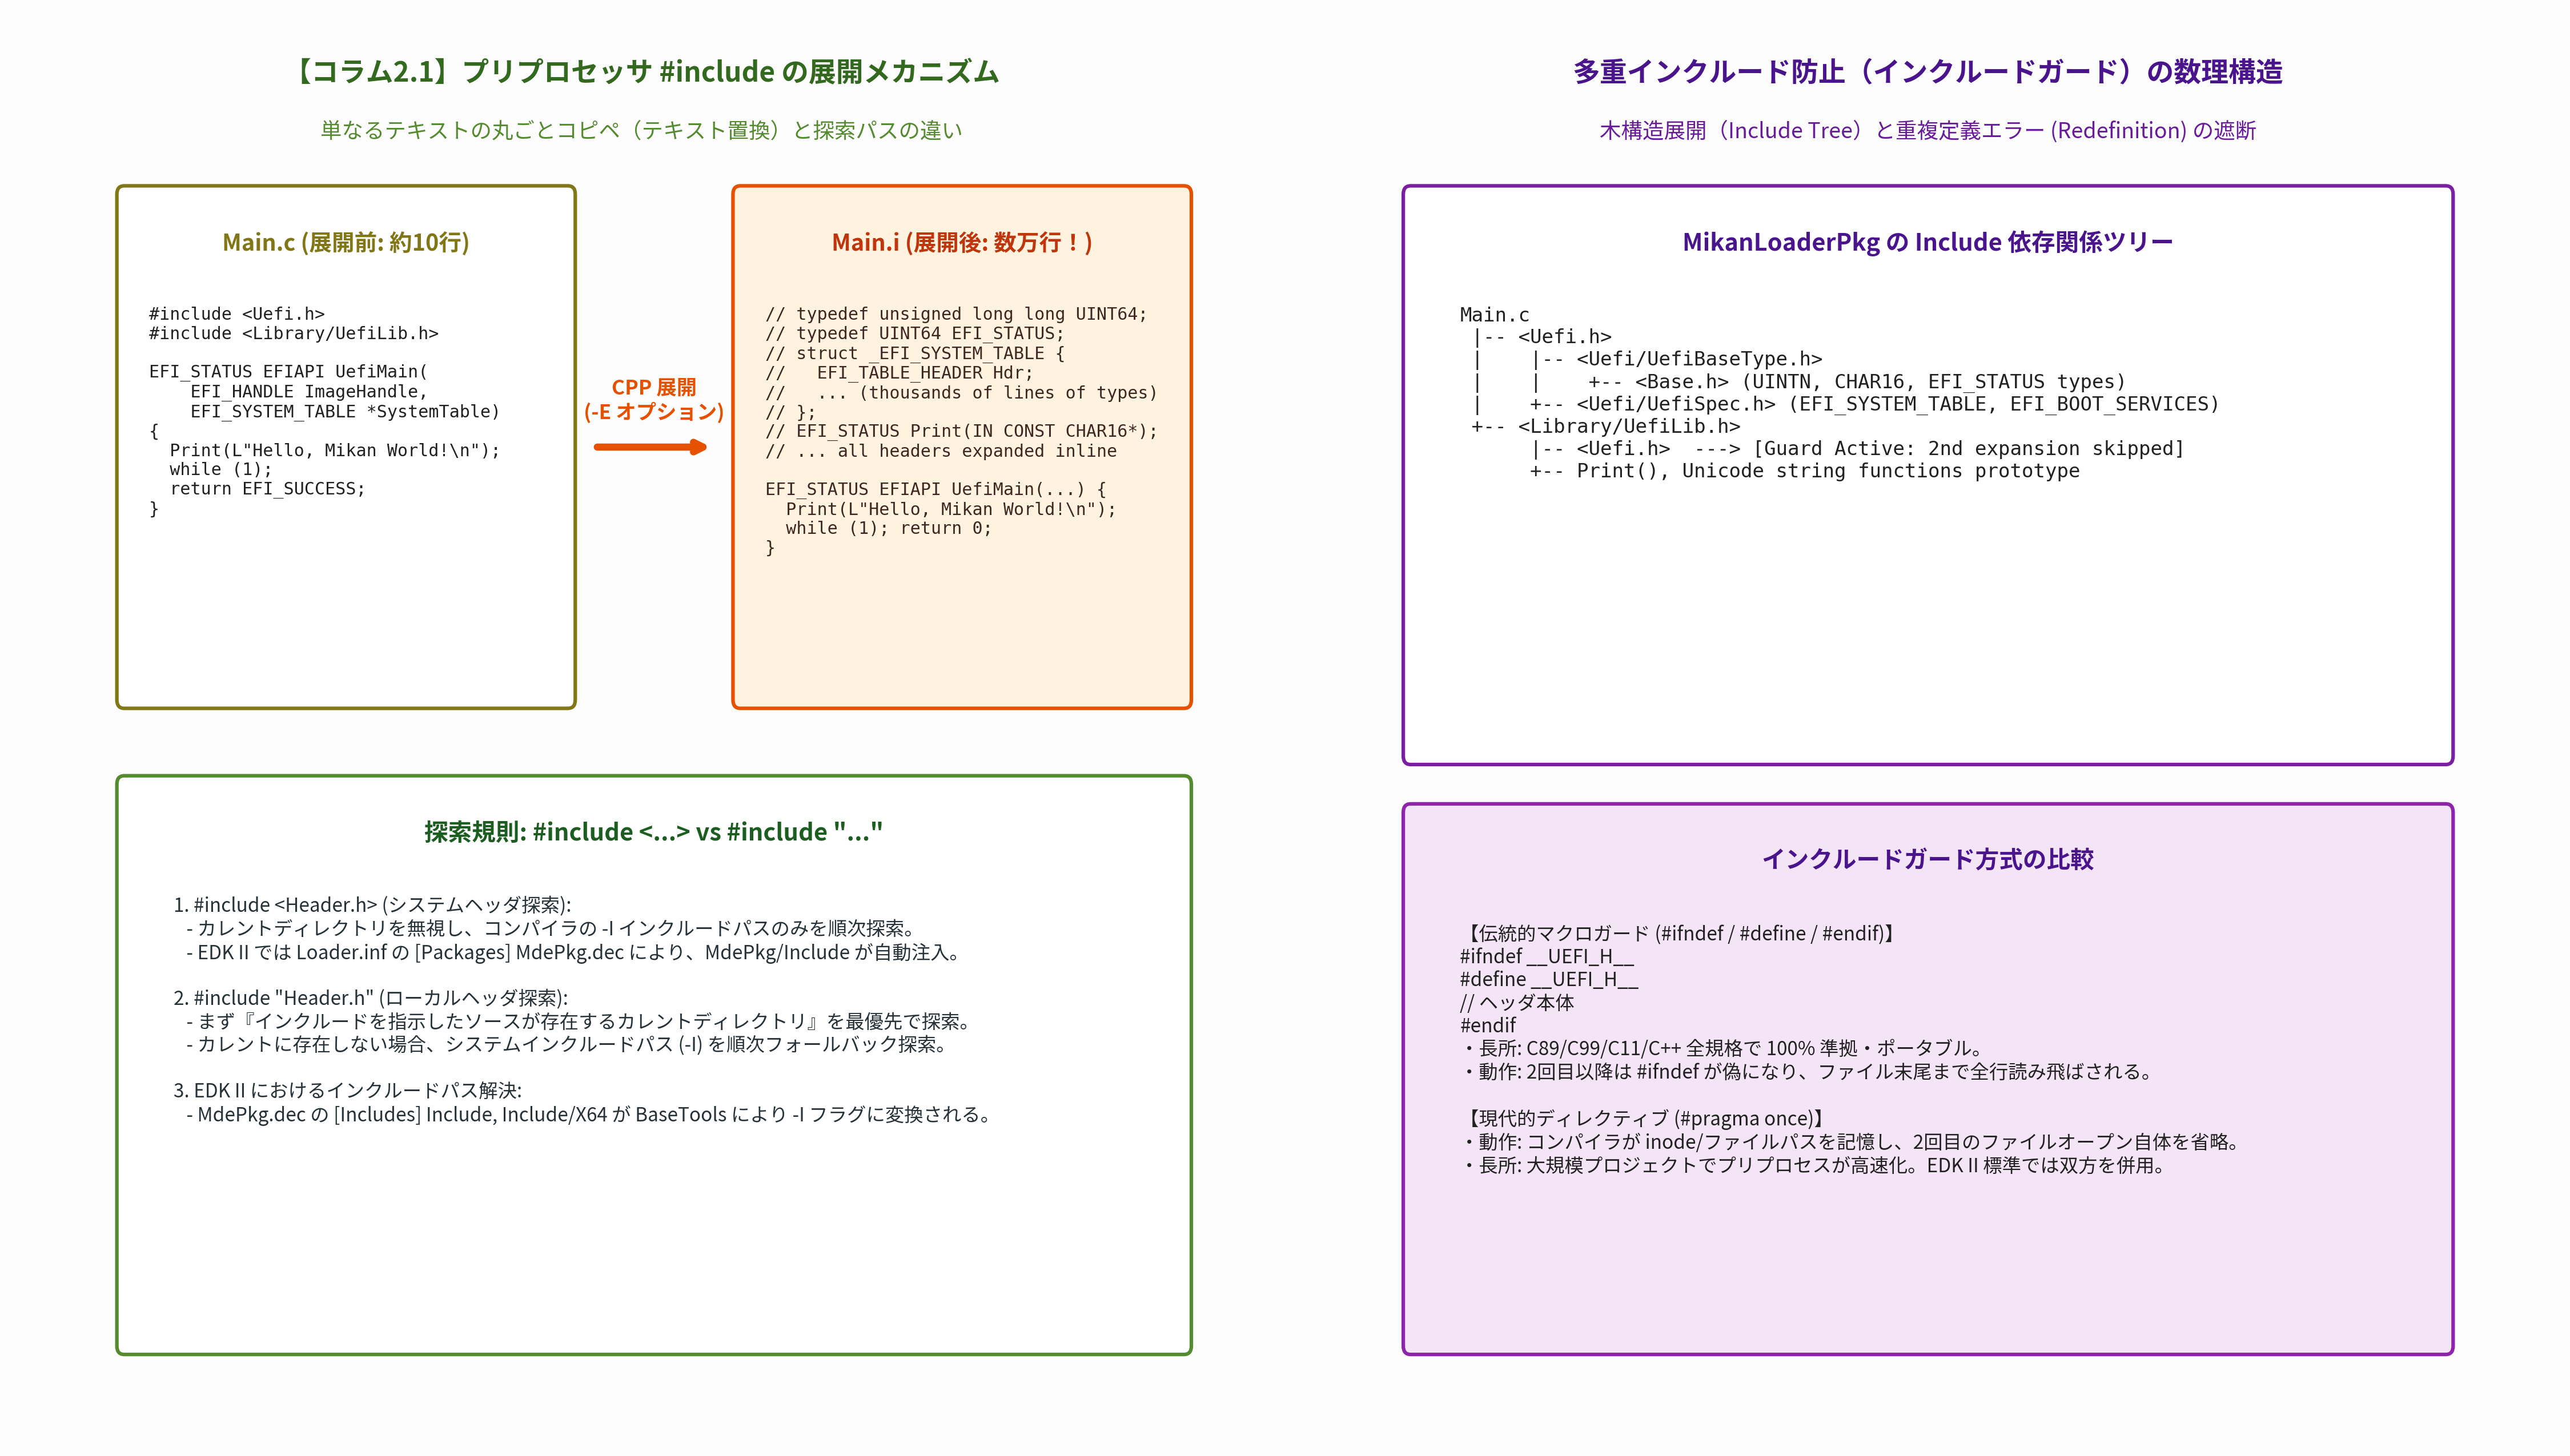

In [6]:
# Figure 2.4 のプロット生成と表示
from pathlib import Path
from IPython.display import Image, display
from common.os_sim import plot_preprocessor_include_expansion_and_tree

fig_path = Path("result/fig2_04_preprocessor_include_expansion_and_tree.png")
plot_preprocessor_include_expansion_and_tree(fig_path)
display(Image(filename=str(fig_path)))


## 7. C++20 による対話型コンパイル検証 & UEFI 環境シミュレーション

MikanOS の学習を UEFI 実機や QEMU の再起動なしに対話的に進めるため、ホスト側 C++20（`g++ -std=c++20`）で UEFI の型システム、UTF-16LE 文字列処理、仮想コンソール `Print()`、およびプリプロセッサ展開エンジンを単体シミュレーションした検証プログラム `src/ch02/uefi_hello_world_sim.cpp` を実行します。


In [7]:
# C++20 スタンドアロン検証プログラムのコンパイル & デモ実行
proj_root = Path.cwd().resolve()
if proj_root.name == "2":
    proj_root = proj_root.parent

cpp_src = proj_root / "src" / "ch02" / "uefi_hello_world_sim.cpp"
bin_target = Path("/tmp/uefi_hello_world_sim")

!g++ -std=c++20 -O2 -Wall -Wextra {cpp_src} -o {bin_target}
!{bin_target} --demo


[PASS] All Chapter 2.2 UEFI C++20 Verification Tests Succeeded!
   MikanOS Chapter 2.2: EDK II Hello World & Preprocessor Demo   

--- 1. UEFI Status Code Architecture (64-bit Bitmask) ---
Status: EFI_SUCCESS              Hex: 0x0000000000000000 IsError: NO  (Bit 63=0) Code: 0
Status: EFI_LOAD_ERROR           Hex: 0x8000000000000001 IsError: YES (Bit 63=1) Code: 1
Status: EFI_INVALID_PARAMETER    Hex: 0x8000000000000002 IsError: YES (Bit 63=1) Code: 2
Status: EFI_BUFFER_TOO_SMALL     Hex: 0x8000000000000005 IsError: YES (Bit 63=1) Code: 5

--- 2. UTF-16LE Memory Representation of L"Hello, Mikan World!\n" ---
Offset  Bytes(LE)   CodePoint   Character
-----------------------------------------
+0000   48 00       0x0048      'H'
+0002   65 00       0x0065      'e'
+0004   6C 00       0x006C      'l'
+0006   6C 00       0x006C      'l'
+0008   6F 00       0x006F      'o'
+0010   2C 00       0x002C      ','
+0012   20 00       0x0020      ' '
+0014   4D 00       0x004D      'M'
+0016   69 0

## 8. EDK II 実環境でのビルド手順と QEMU 動作検証

実環境の Linux / WSL2 上で EDK II を用いて `Main.c` をコンパイルし、QEMU 上で起動する標準手順は以下の通りです：

### 8.1 EDK II ビルドの実行
```bash
$ cd $HOME/edk2
$ source edksetup.sh
$ build
```

EDK II の `build` コマンドは、`Conf/target.txt` で設定されたターゲット（`ACTIVE_PLATFORM = MikanLoaderPkg/MikanLoaderPkg.dsc`, `TARGET_ARCH = X64`, `TOOL_CHAIN_TAG = CLANG38`）を読み込み、以下の出力先に PE32+ バイナリを生成します：

```text
$HOME/edk2/Build/MikanLoaderX64/DEBUG_CLANG38/X64/Loader.efi
```

### 8.2 FAT32 ディスクイメージへの配置と QEMU 起動
```bash
# FAT32 ディスクイメージの作成と UEFI 標準パスへのコピー
$ qemu-img create -f raw disk.img 64M
$ mkfs.fat -n 'MIKAN OS' -s 2 -f 2 -R 32 -F 32 disk.img
$ mkdir -p mnt
$ sudo mount -o loop disk.img mnt
$ sudo mkdir -p mnt/EFI/BOOT
$ sudo cp $HOME/edk2/Build/MikanLoaderX64/DEBUG_CLANG38/X64/Loader.efi mnt/EFI/BOOT/BOOTX64.EFI
$ sudo umount mnt

# OVMF を用いて QEMU 起動
$ qemu-system-x86_64 \
    -bios $HOME/osbook/devenv/OVMF_CODE.fd \
    -hda disk.img
```

起動すると、OVMF のブートマネージャが `\EFI\BOOT\BOOTX64.EFI` をロードし、画面に黄色または白色のフォントで **`Hello, Mikan World!`** と表示され、`while (1);` により静止します。


## 9. 第2章 2.2節のまとめと次節への展望

### 9.1 本節の重要ポイント総括

| トピック | キーポイント |
|---|---|
| **MikanLoaderPkg** | `MikanLoaderPkg.dec` (GUID宣言), `Loader.inf` (モジュール構成), `MikanLoaderPkg.dsc` (依存性注入) の3大メタ定義ファイルにより公式 EDK II ビルド環境を構築。 |
| **UEFI ABI** | `EFIAPI` は Microsoft x64 呼び出し規約（`RCX`, `RDX`, `R8`, `R9`, 32B Shadow Space）。`EFI_STATUS` は最上位ビット（Bit 63）がエラーフラグ。 |
| **UTF-16LE (CHAR16)** | `L"..."` は 16ビット文字（2バイト/文字）のリトルエンディアン配列で表現され、末尾に `0x0000` の終端を持つ。 |
| **while (1);** | ブートローダがファームウェア（UEFI Shell / Boot Manager）に早期復帰して画面がクリアされるのを防ぐため、CPU を無限ループで静止させる。 |
| **コラム2.1 インクルード** | `#include` はプリプロセッサによるテキストの丸ごとコピペ。`<...>` はシステム探索、`"..."` はカレントディレクトリ優先。多重インクルードガード（`#ifndef`）により再定義エラーを防止。 |

---

### 9.2 次節（2.3節）への展望
画面への文字表示に成功した自作ブートローダですが、本格的な OS カーネルをロードして起動するためには、PC の **「メモリ構造（メモリマップ）」** を正確に把握しなければなりません。
次節 **2.3「メインメモリ」** では、x86-64 アーキテクチャの物理アドレス空間、RAM と MMIO（*Memory-Mapped I/O*）領域、ファームウェア予約領域の配置と数理について学んでいきます！
